In [2]:
import sys 
sys.path.append('/Users/amalyajohnson/Desktop/SpectraScope/spectrascope2/')
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
from spectrascope.SpectraScope import *
from spectrascope.features import * 
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import SPA 

In [26]:
import scipy 
scipy.__version__

'1.13.1'

In [28]:
import pyts 
pyts.__version__

'0.13.0'

In [21]:
import sklearn 
sklearn.__version__

'1.5.0'

In [5]:
fnX = '/Users/amalyajohnson/Desktop/Spectrascope/spectrascope2/tests/test_files/X_testfile.npy'
fny = '/Users/amalyajohnson/Desktop/Spectrascope/spectrascope2/tests/test_files/y_testfile.npy'
X = np.load(fnX)
y = np.load(fny)

In [6]:
x = np.linspace(4969.0, 5021.0, 200),

In [7]:
ss = SpectraScope(X = X, y = y, specnames=['pdf', 'xanes'], yname='nn')

no random seed selected, when splitting data, will always give different split
saving to /examples/models, change save_path kwarg if youd like to change


In [8]:
ss.add_x_axis(specname='xanes', value=np.linspace(4969.0, 5021.0, 200))
ss.add_x_axis(specname='pdf', value=np.linspace(0,10,200))

In [9]:
ss.add_feature('xanes', 'pointwise_features', xrange = ss.xanes_xaxis)
ss.add_feature('pdf', 'pointwise_features', xrange = ss.pdf_xaxis)

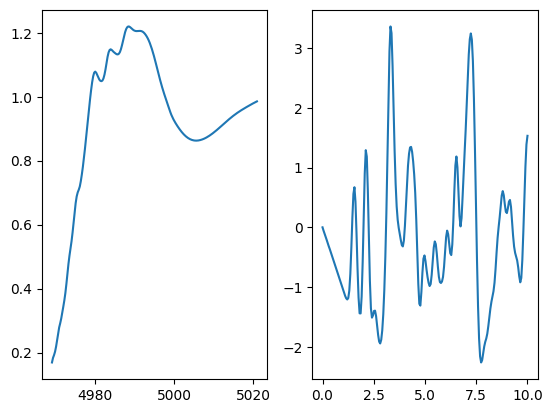

In [10]:
f, (ax1, ax2) = plt.subplots(1,2)
ax1.plot(ss.xanes_xaxis, ss.xanes_pointwise_features[0])
ax2.plot(ss.pdf_xaxis, ss.pdf_pointwise_features[0])

In [11]:
ss.add_feature('xanes', 'polynomial_featuresall')
ss.add_feature('xanes', 'polynomial_featuresN', N=5)
ss.add_feature('xanes', 'featureagg', n_clusters=10)
ss.add_feature('xanes', 'pca', n_components=10)
ss.add_feature('xanes', 'cdf')
ss.add_feature('xanes', 'cwt')

In [12]:
x2 = np.linspace(4969.0, 5021.0, 200)
temp = spectral_features(x2, X[0])

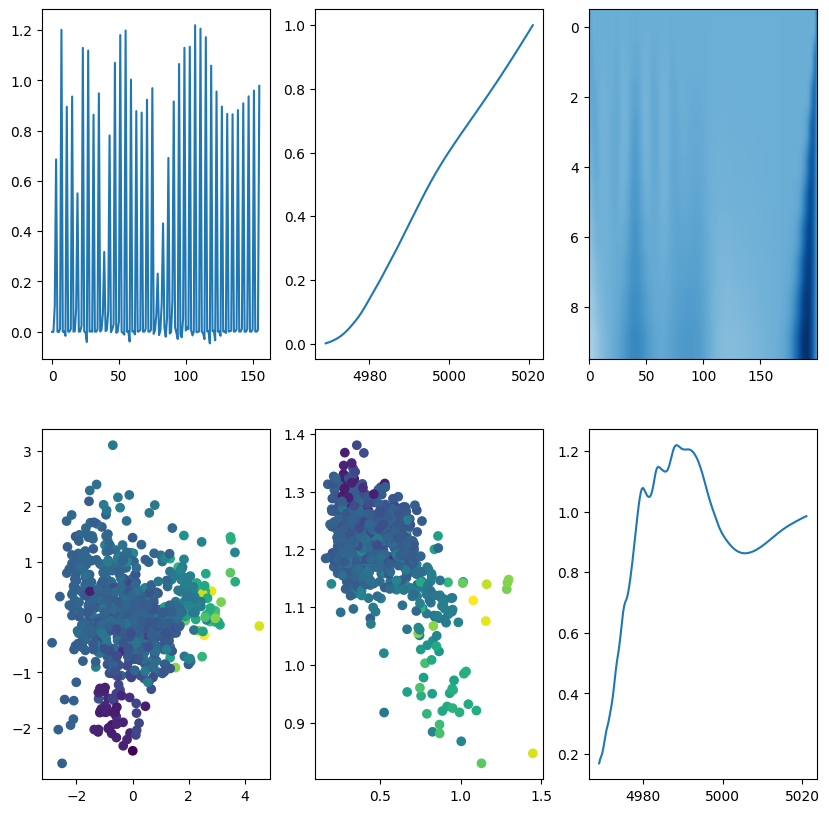

In [13]:
f, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2,3, figsize=(10,10))
ax1.plot(np.arange(156), ss.xanes_polynomial_featuresall[0][:-1])
ax2.plot(ss.xanes_xaxis, ss.xanes_cdf[0])

cwt_coefs = ss.xanes_cwt[0]
ax3.imshow(cwt_coefs.reshape(10,200), aspect='auto', cmap='Blues',
           vmax=(np.abs(cwt_coefs)).max(), vmin=-(np.abs(cwt_coefs)).max())

ax4.scatter(ss.xanes_pca[:,0], ss.xanes_pca[:,1], c = ss.nn)
ax5.scatter(ss.xanes_featureagg[:,0], ss.xanes_featureagg[:,1], c = ss.nn)

ax6.plot(ss.xanes_xaxis, ss.xanes[0])

In [14]:
ss.combine_feature('xanes_pointwise_features', 'pdf_pointwise_features')

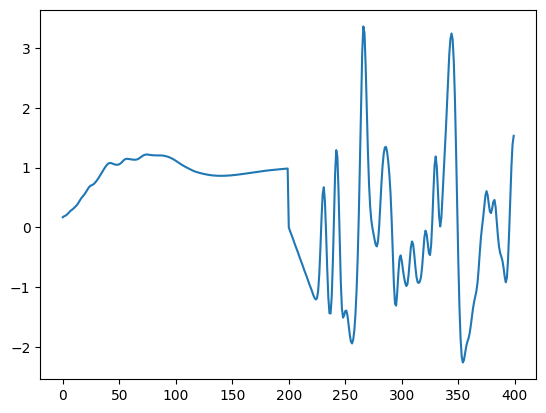

In [15]:
plt.plot(ss.xanes_pdf_pointwise_features[0])

In [16]:
ridge_kwargs = {'model':Ridge(), 
                             'param_grid': {'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                                           'fit_intercept':[True], 
                            }, 'refit':True, 
                             'metric':mean_squared_error}
                             
                             
lasso_kwargs = {'model':Lasso(), 
                'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'fit_intercept':[True]
                    },
                'refit':True,
                'metric':mean_squared_error}

en_kwargs = {'model':ElasticNet(), 
                'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'l1_ratio': [0.1, 0.5, 0.9],
                            'fit_intercept':[True]
                            },
                'refit':True,
                'metric':mean_squared_error}

RF_kwargs = {'model':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[50,100,200, 300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [10,35, None]},
                'refit':True,
                'metric':mean_squared_error}

RF_kwargs = {'model':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [50, None]},
                'refit':True,
                'metric':mean_squared_error}

lcen_kwargs = {'l1_ratio':[0.01,0.1, 0.3, 0.5, 0.6, 0.99], 
               'K_fold':5, 
               'cv_method':'Kfold', 
               'n_jobs':-2,
               'alpha':5, 
               'degree':[1,2],
               'trans_type':'poly', 
               'LCEN_cutoff':5e-2, 
               'LCEN_interaction':False, 
               'scale_X':True, 
               'scale_y':True}

In [17]:
feats = {'pointwise_features':[{'specname':'xanes', 'xrange':ss.xanes_xaxis},
                               {'specname':'pdf', 'xrange':ss.pdf_xaxis}],
         'polynomial_featuresall':[
             { 'specname':'xanes', 'Narr':np.array([4,5,10,20]), 'degree':3},
             { 'specname':'pdf', 'Narr':np.array([4,5,10,20]), 'degree':3}], 
        'cdf': [{ 'specname':'xanes'}]
         }
sk_kwargs = [lasso_kwargs, ridge_kwargs] #, en_kwargs]#, RF_kwargs]
multi_modal = [('xanes_pointwise_features', 'pdf_pointwise_features')] #, 
            #    ('xanes_polynomial_featuresall', 'pdf_polynomial_featuresall')]
ss.random_seed = 12
ss.do_all(feats, 'nn', 0.25, sk_kwargs=sk_kwargs, lcen_kwargs=lcen_kwargs, 
                multi_modal=multi_modal)

Beginning variable selection runs. There are 12 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
=== Residual Analysis ===
RMSE = 0.03497606805786759
APE = 1.1547331554830578
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Beginning variable selection runs. There are 12 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
=== Residual Analysis ===
RMSE = 0.05253915273553087
APE = 1.9165488200692207
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Beginning variable selection runs. There are 12 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
=== Residual Analysis ===
RMSE = 0.036385456492743426
APE = 1.3358246948565144
The best model is LCEN. 

In [18]:
import seaborn as sns

<Axes: >

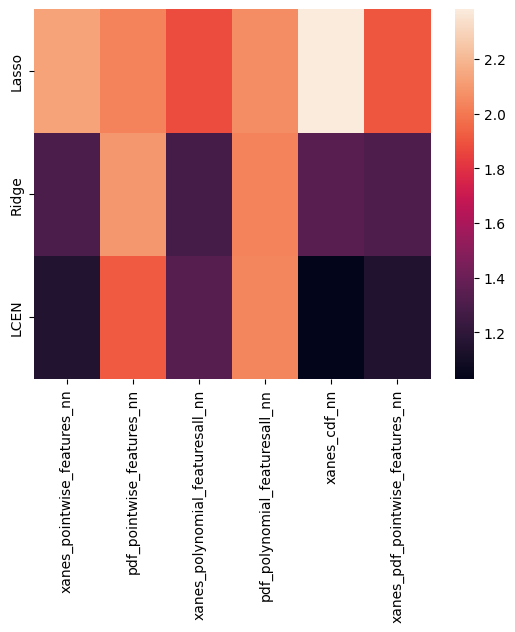

In [19]:
sns.heatmap(pd.DataFrame(ss.best_fits).T)